In [1]:
import sys
sys.path.append("..")

from undirectedGraphsUtils import (
    generateConnectedGraph,
    generateConnectedGraphRegularK,
    graphComponents,

    generateEdgeWeights,
    save_weights_to_file,
    load_weights_from_file,

    dijkstra,
    print_dijkstra_results,
    dijkstra_matrix,

    findCentralNode,
    findMinimaxNode,

    kruskalMST,

    graphDisplay,
)

Lista sąsiedztwa:
1: [2, 3, 7]
2: [1, 3, 4, 7, 8]
3: [1, 2, 5, 6, 7]
4: [2]
5: [3, 6, 7]
6: [3, 5]
7: [1, 2, 3, 5]
8: [2]

Wagi krawędzi:
(1, 2): 4
(1, 3): 3
(1, 7): 7
(2, 3): 5
(2, 4): 5
(2, 7): 8
(2, 8): 9
(3, 5): 5
(3, 6): 7
(3, 7): 6
(5, 6): 2
(5, 7): 9


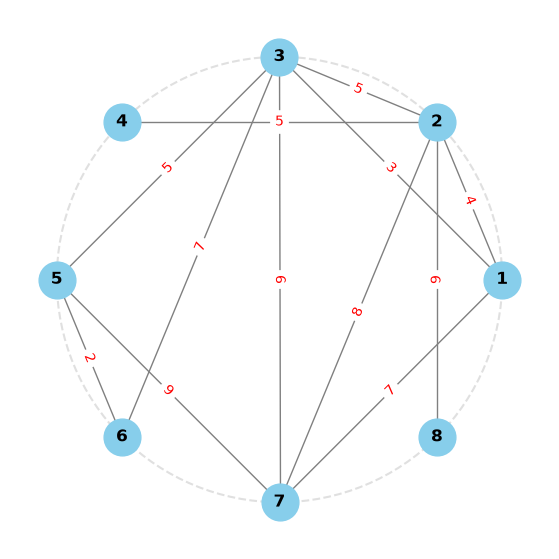

In [2]:
node_num = 8
edge_num = 12

graph = generateConnectedGraph(
    node_num=node_num,
    edge_num=edge_num
)

weights = generateEdgeWeights(
    adjacent_list=graph,
    min_weight=1,
    max_weight=10
)

print("Lista sąsiedztwa:")
for i, neighbors in enumerate(graph, start=1):
    print(f"{i}: {neighbors}")

print("\nWagi krawędzi:")
for edge, weight in sorted(weights.items()):
    print(f"{edge}: {weight}")

# Wizualizacja grafu
graphDisplay(graph, weights=weights)

In [3]:
start_node = 1

print_dijkstra_results(
    adjacent_list=graph,
    weights=weights,
    dijkstra_start=start_node
)

Shortest paths from vertex 1:
To vertex 1: path = 1, distance = 0
To vertex 2: path = 1 -> 2, distance = 4
To vertex 3: path = 1 -> 3, distance = 3
To vertex 4: path = 1 -> 2 -> 4, distance = 9
To vertex 5: path = 1 -> 3 -> 5, distance = 8
To vertex 6: path = 1 -> 3 -> 6, distance = 10
To vertex 7: path = 1 -> 7, distance = 7
To vertex 8: path = 1 -> 2 -> 8, distance = 13


In [4]:
distance_matrix = dijkstra_matrix(
    adjacent_list=graph,
    weights=weights
)

print("Macierz odległości:")

for row in distance_matrix:
    print(" ".join(f"{distance:5}" for distance in row))

Macierz odległości:
    0     4     3     9     8    10     7    13
    4     0     5     5    10    12     8     9
    3     5     0    10     5     7     6    14
    9     5    10     0    15    17    13    14
    8    10     5    15     0     2     9    19
   10    12     7    17     2     0    11    21
    7     8     6    13     9    11     0    17
   13     9    14    14    19    21    17     0


In [5]:
central_node, distance_sum = findCentralNode(
    adjacent_list=graph,
    weights=weights
)

print("Centrum grafu:", central_node)
print("Suma odległości:", distance_sum)

minimax_node, max_distance = findMinimaxNode(
    adjacent_list=graph,
    weights=weights
)

print("\nCentrum minimax:", minimax_node)
print("Odległość do najdalszego wierzchołka:", max_distance)

Centrum grafu: 3
Suma odległości: 50

Centrum minimax: 2
Odległość do najdalszego wierzchołka: 12


Krawędzie minimalnego drzewa rozpinającego:
(5, 6): waga = 2
(1, 3): waga = 3
(1, 2): waga = 4
(2, 4): waga = 5
(3, 5): waga = 5
(3, 7): waga = 6
(2, 8): waga = 9

Łączna waga drzewa rozpinającego: 34


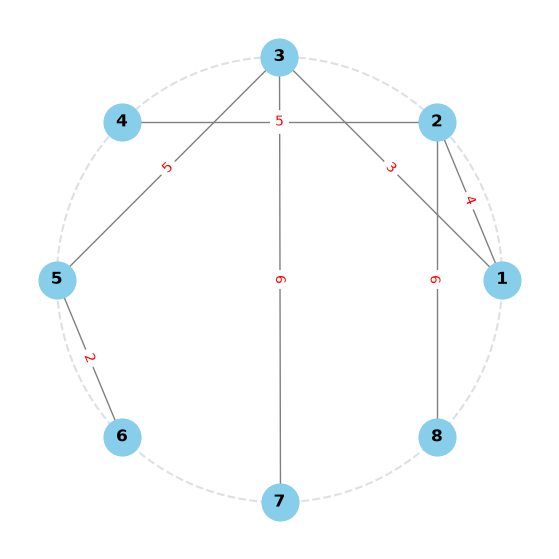

In [6]:
mst_edges, mst_weights, total_weight = kruskalMST(
    adjacent_list=graph,
    weights=weights
)

print("Krawędzie minimalnego drzewa rozpinającego:")

for edge in mst_edges:
    print(f"{edge}: waga = {mst_weights[edge]}")

print("\nŁączna waga drzewa rozpinającego:", total_weight)

mst_graph = [[] for _ in range(node_num)]

for u, v in mst_edges:
    mst_graph[u - 1].append(v)
    mst_graph[v - 1].append(u)

graphDisplay(
    mst_graph,
    filename="minimalne_drzewo_rozpinajace",
    weights=mst_weights
)